In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Dataset directory
DATA_PATH = Path("../csv_source_files")

# Load livestock datasets
livestock_population_df = pd.read_csv(
    DATA_PATH / "07_livestock_population_yearly.csv"
)

livestock_products_df = pd.read_csv(
    DATA_PATH / "08_livestock_products_yearly.csv"
)

print("Livestock datasets loaded successfully!")

Livestock datasets loaded successfully!


### Livestock Population

In [32]:
print("LIVESTOCK POPULATION")
print("Shape:", livestock_population_df.shape)
display(livestock_population_df.head())
print("\nColumns:", livestock_population_df.columns.tolist())


LIVESTOCK POPULATION
Shape: (110, 3)


,Fiscal_Year,Category,Population
0,2024/25,Cattle,5141391
1,2024/25,Buffaloes,3294723
2,2024/25,Sheep,652742
3,2024/25,Goat,15954080
4,2024/25,Pigs,1480832



Columns: ['Fiscal_Year', 'Category', 'Population']


In [33]:
# Available livestock categories
print("LIVESTOCK CATEGORIES")
print(livestock_population_df["Category"].unique())

# Available fiscal years
print("\nFISCAL YEARS")
print(sorted(livestock_population_df["Fiscal_Year"].unique()))

# Records per fiscal year
print("\nPOPULATION RECORDS PER YEAR")
display(livestock_population_df.groupby("Fiscal_Year").size())


LIVESTOCK CATEGORIES
<StringArray>
[           'Cattle',         'Buffaloes',             'Sheep',
              'Goat',              'Pigs',              'Fowl',
              'Duck',       'Milking Cow', 'Milking Buffaloes',
        'Laying Hen',       'Laying Duck']
Length: 11, dtype: str

FISCAL YEARS
['2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021/22', '2022/23', '2023/24', '2024/25']

POPULATION RECORDS PER YEAR


Fiscal_Year
2015/16    11
2016/17    11
2017/18    11
2018/19    11
2019/20    11
2020/21    11
2021/22    11
2022/23    11
2023/24    11
2024/25    11
dtype: int64

In [34]:
# Main livestock population categories
main_livestock = [
    "Cattle",
    "Buffaloes",
    "Sheep",
    "Goat",
    "Pigs",
    "Fowl",
    "Duck"
]

livestock_main_df = livestock_population_df[
    livestock_population_df["Category"].isin(main_livestock)
].copy()

# Population by category across fiscal years
population_pivot = livestock_main_df.pivot(
    index="Fiscal_Year",
    columns="Category",
    values="Population"
)

display(population_pivot)

Category,Buffaloes,Cattle,Duck,Fowl,Goat,Pigs,Sheep
Fiscal_Year,,,,,,,
2015/16,5168809,7302808,392255,68630638,10986114,1291308,800658
2016/17,5177998,7347487,394775,70007151,11165099,1328036,801975
2017/18,5277819,7376306,404670,72245732,11647319,1435369,800749
2018/19,5308664,7385035,416400,75709330,12283752,1488338,798889
2019/20,5257591,7458885,427226,82598879,12811953,1519593,806079
2020/21,5159931,7466841,432226,73418077,13442614,1588838,793725
2021/22,5132931,7413196,605943,66803116,13990703,1504623,771204
2022/23,3081061,4750329,1325998,65205250,14541244,1357507,501848
2023/24,3307031,5198388,796758,56916567,15289954,1497411,633222


In [35]:
# Total population across all 10 years by category
population_contribution = (
    livestock_main_df.groupby("Category")["Population"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Calculate percentage contribution
population_contribution["Contribution_%"] = (
    population_contribution["Population"]
    / population_contribution["Population"].sum()
) * 100

display(population_contribution)

,Category,Population,Contribution_%
0,Fowl,687926420,71.589805
1,Goat,132112832,13.748464
2,Cattle,66840666,6.955846
3,Buffaloes,46166558,4.804373
4,Pigs,14491855,1.508111
5,Sheep,7361091,0.766040
6,Duck,6028486,0.627361


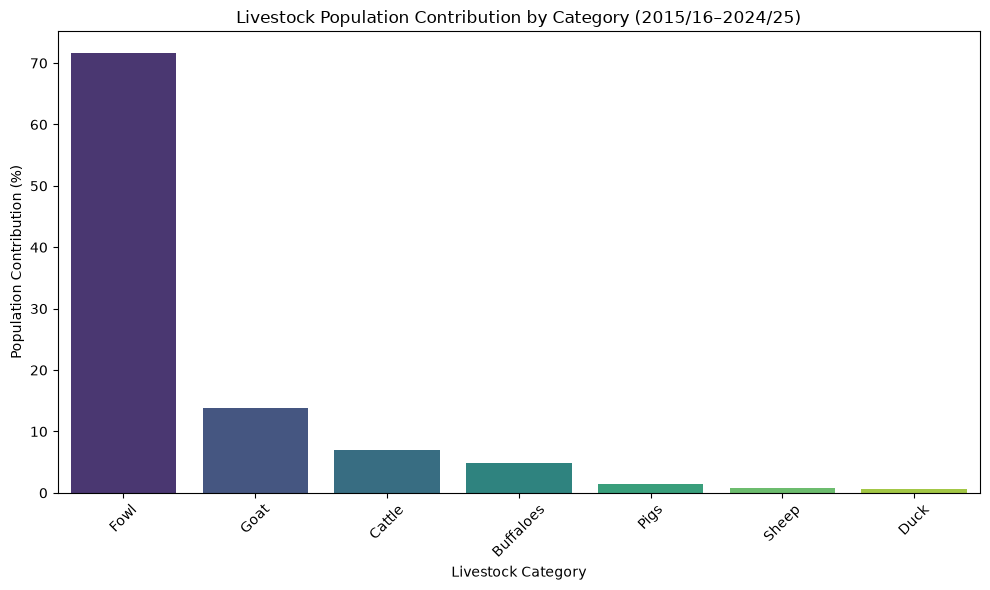

In [36]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=population_contribution,
    x="Category",
    y="Contribution_%",
    hue="Category",
    palette="viridis",
    legend=False
)

plt.title("Livestock Population Contribution by Category (2015/16–2024/25)")
plt.xlabel("Livestock Category")
plt.ylabel("Population Contribution (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

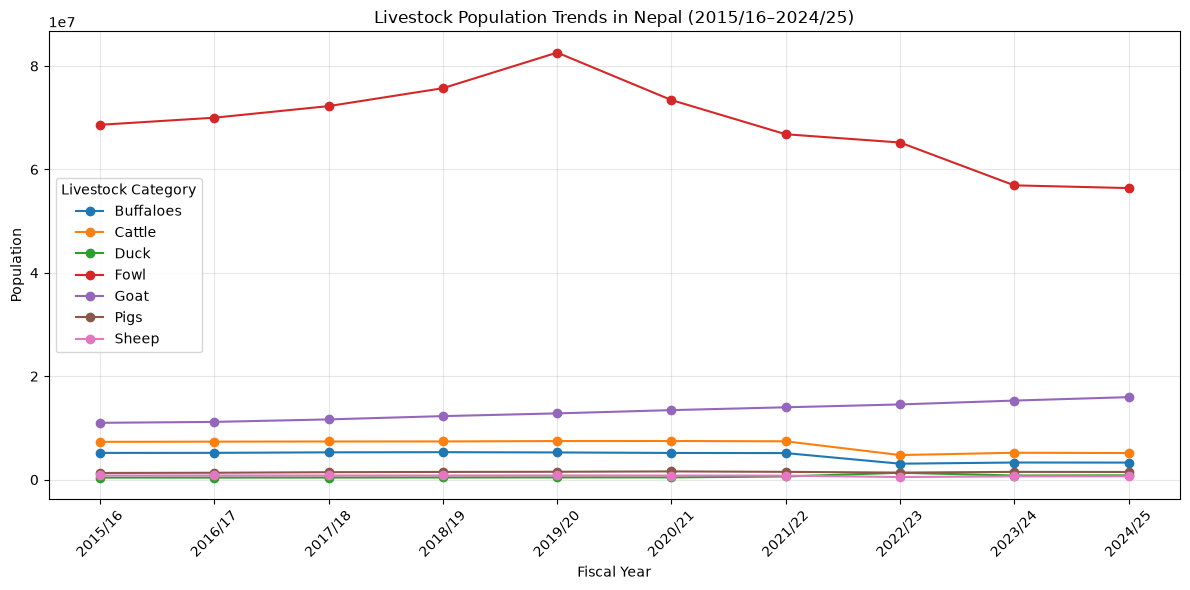

In [37]:
plt.figure(figsize=(12, 6))

for category in population_pivot.columns:
    plt.plot(
        population_pivot.index,
        population_pivot[category],
        marker="o",
        label=category
    )

plt.title("Livestock Population Trends in Nepal (2015/16–2024/25)")
plt.xlabel("Fiscal Year")
plt.ylabel("Population")
plt.xticks(rotation=45)
plt.legend(title="Livestock Category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Calculate year-over-year percentage change
population_growth = population_pivot.pct_change() * 100

display(population_growth.round(2))

Category,Buffaloes,Cattle,Duck,Fowl,Goat,Pigs,Sheep
Fiscal_Year,,,,,,,
2015/16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016/17,0.18,0.61,0.64,2.01,1.63,2.84,0.16
2017/18,1.93,0.39,2.51,3.20,4.32,8.08,-0.15
2018/19,0.58,0.12,2.90,4.79,5.46,3.69,-0.23
2019/20,-0.96,1.00,2.60,9.10,4.30,2.10,0.90
2020/21,-1.86,0.11,1.17,-11.11,4.92,4.56,-1.53
2021/22,-0.52,-0.72,40.19,-9.01,4.08,-5.30,-2.84
2022/23,-39.97,-35.92,118.83,-2.39,3.94,-9.78,-34.93
2023/24,7.33,9.43,-39.91,-12.71,5.15,10.31,26.18


In [ ]:
#Overall population change
population_change = pd.DataFrame({
    "Initial_Population": population_pivot.iloc[0],
    "Final_Population": population_pivot.iloc[-1]
})

population_change["Absolute_Change"] = (
    population_change["Final_Population"]
    - population_change["Initial_Population"]
)

population_change["Growth_%"] = (
    population_change["Absolute_Change"]
    / population_change["Initial_Population"]
) * 100

display(population_change.sort_values("Growth_%", ascending=False).round(2))

,Initial_Population,Final_Population,Absolute_Change,Growth_%
Category,,,,
Duck,392255,832235,439980,112.17
Goat,10986114,15954080,4967966,45.22
Pigs,1291308,1480832,189524,14.68
Fowl,68630638,56391680,-12238958,-17.83
Sheep,800658,652742,-147916,-18.47
Cattle,7302808,5141391,-2161417,-29.60
Buffaloes,5168809,3294723,-1874086,-36.26


In [ ]:
# Productive Livestock pivot table
productive_categories = [
    "Milking Cow",
    "Milking Buffaloes",
    "Laying Hen",
    "Laying Duck"
]

productive_livestock_df = livestock_population_df[
    livestock_population_df["Category"].isin(productive_categories)
].copy()

productive_pivot = productive_livestock_df.pivot(
    index="Fiscal_Year",
    columns="Category",
    values="Population"
)

display(productive_pivot)

Category,Laying Duck,Laying Hen,Milking Buffaloes,Milking Cow
Fiscal_Year,,,,
2015/16,180927,12353515,1355384,1026135
2016/17,183940,12388889,1509512,1029529
2017/18,186912,12517558,1535948,1039538
2018/19,190747,12526979,1560584,1078775
2019/20,191701,12927842,1635492,1166156
2020/21,220531,11374011,1630642,1209040
2021/22,302472,10131642,1666827,1223061
2022/23,661937,12725053,851272,916578
2023/24,444292,13487122,1251323,1063189


In [ ]:
# Calculate year-over-year percentage change for productive livestock

productive_growth = productive_pivot.pct_change() * 100

display(productive_growth.round(2))

Category,Laying Duck,Laying Hen,Milking Buffaloes,Milking Cow
Fiscal_Year,,,,
2015/16,NaN,NaN,NaN,NaN
2016/17,1.67,0.29,11.37,0.33
2017/18,1.62,1.04,1.75,0.97
2018/19,2.05,0.08,1.60,3.77
2019/20,0.50,3.20,4.80,8.10
2020/21,15.04,-12.02,-0.30,3.68
2021/22,37.16,-10.92,2.22,1.16
2022/23,118.84,25.60,-48.93,-25.06
2023/24,-32.88,5.99,46.99,16.00


In [ ]:
# overall productive livestock population change
productive_change = pd.DataFrame({
    "Initial_Population": productive_pivot.iloc[0],
    "Final_Population": productive_pivot.iloc[-1]
})

productive_change["Absolute_Change"] = (
    productive_change["Final_Population"]
    - productive_change["Initial_Population"]
)

productive_change["Growth_%"] = (
    productive_change["Absolute_Change"]
    / productive_change["Initial_Population"]
) * 100

display(
    productive_change.sort_values(
        "Growth_%", ascending=False
    ).round(2)
)

,Initial_Population,Final_Population,Absolute_Change,Growth_%
Category,,,,
Laying Duck,180927,321908,140981,77.92
Milking Cow,1026135,1055828,29693,2.89
Laying Hen,12353515,12405021,51506,0.42
Milking Buffaloes,1355384,965920,-389464,-28.73


### Livestock Products

In [43]:

print("\nLIVESTOCK PRODUCTS")
print("Shape:", livestock_products_df.shape)
display(livestock_products_df.head())
print("\nColumns:", livestock_products_df.columns.tolist())


LIVESTOCK PRODUCTS
Shape: (150, 3)


,Fiscal_Year,Product,Value
0,2024/25,Milk Production (Mt.),2718177.0
1,2024/25,Cow Milk (Mt.),1302094.0
2,2024/25,Buff. Milk (Mt.),1416083.0
3,2024/25,Meat (Net) Production (Mt.),456430.0
4,2024/25,Buff (Mt.),141649.0



Columns: ['Fiscal_Year', 'Product', 'Value']


In [44]:
# Available livestock products
print("\nLIVESTOCK PRODUCTS")
print(livestock_products_df["Product"].unique())

print("\nPRODUCT RECORDS PER YEAR")
display(livestock_products_df.groupby("Fiscal_Year").size())


LIVESTOCK PRODUCTS
<StringArray>
[       'Milk Production (Mt.)',               'Cow Milk (Mt.)',
             'Buff. Milk (Mt.)',  'Meat (Net) Production (Mt.)',
                   'Buff (Mt.)',         'Mutton (Sheep) (Mt.)',
                 'Chevon (Mt.)',                   'Pork (Mt.)',
                'Chicken (Mt.)',                   'Duck (Mt.)',
 'Egg Production (‘000 Number)',        'Hen Egg (‘000 Number)',
        'Duck Egg(‘000 Number)',         'Wool Production(Kg.)',
         'Fish Production (Mt)']
Length: 15, dtype: str

PRODUCT RECORDS PER YEAR


Fiscal_Year
2015/16    15
2016/17    15
2017/18    15
2018/19    15
2019/20    15
2020/21    15
2021/22    15
2022/23    15
2023/24    15
2024/25    15
dtype: int64

In [51]:
milk_products = [
    "Milk Production (Mt.)",
    "Cow Milk (Mt.)",
    "Buff. Milk (Mt.)"
]

milk_df = livestock_products_df[
    livestock_products_df["Product"].isin(milk_products)
].copy()

milk_pivot = milk_df.pivot(
    index="Fiscal_Year",
    columns="Product",
    values="Value"
)

display(milk_pivot)

Product,Buff. Milk (Mt.),Cow Milk (Mt.),Milk Production (Mt.)
Fiscal_Year,,,
2015/16,1210441.0,643806.0,1854247.0
2016/17,1245954.0,665285.0,1911239.0
2017/18,1338277.0,754126.0,2092403.0
2018/19,1372905.0,795530.0,2168434.0
2019/20,1380600.0,920400.0,2301000.0
2020/21,1419412.0,1060487.0,2479899.0
2021/22,1464802.0,1101812.0,2566614.0
2022/23,1399797.0,1214046.0,2613843.0
2023/24,1402156.0,1281718.0,2683874.0


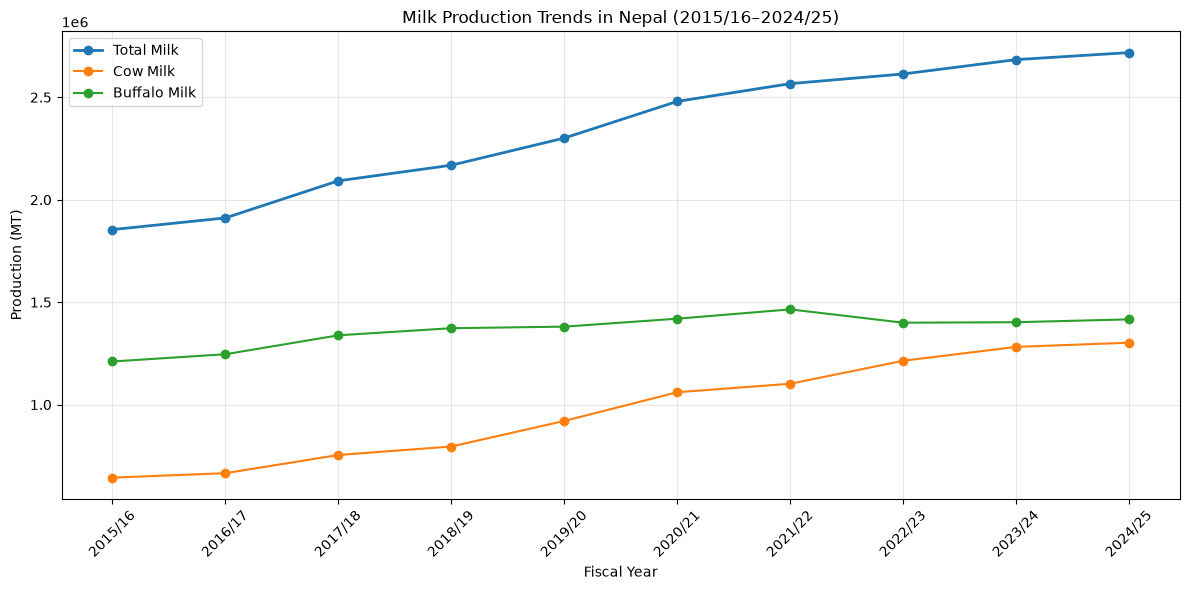

In [52]:
plt.figure(figsize=(12, 6))

plt.plot(
    milk_pivot.index,
    milk_pivot["Milk Production (Mt.)"],
    marker="o",
    linewidth=2,
    label="Total Milk"
)

plt.plot(
    milk_pivot.index,
    milk_pivot["Cow Milk (Mt.)"],
    marker="o",
    label="Cow Milk"
)

plt.plot(
    milk_pivot.index,
    milk_pivot["Buff. Milk (Mt.)"],
    marker="o",
    label="Buffalo Milk"
)

plt.title("Milk Production Trends in Nepal (2015/16–2024/25)")
plt.xlabel("Fiscal Year")
plt.ylabel("Production (MT)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
milk_contribution = milk_pivot.copy()

milk_contribution["Cow_Milk_Share_%"] = (
    milk_contribution["Cow Milk (Mt.)"]
    / milk_contribution["Milk Production (Mt.)"]
) * 100

milk_contribution["Buffalo_Milk_Share_%"] = (
    milk_contribution["Buff. Milk (Mt.)"]
    / milk_contribution["Milk Production (Mt.)"]
) * 100

display(milk_contribution.round(2))

Product,Buff. Milk (Mt.),Cow Milk (Mt.),Milk Production (Mt.),Cow_Milk_Share_%,Buffalo_Milk_Share_%
Fiscal_Year,,,,,
2015/16,1210441.0,643806.0,1854247.0,34.72,65.28
2016/17,1245954.0,665285.0,1911239.0,34.81,65.19
2017/18,1338277.0,754126.0,2092403.0,36.04,63.96
2018/19,1372905.0,795530.0,2168434.0,36.69,63.31
2019/20,1380600.0,920400.0,2301000.0,40.00,60.00
2020/21,1419412.0,1060487.0,2479899.0,42.76,57.24
2021/22,1464802.0,1101812.0,2566614.0,42.93,57.07
2022/23,1399797.0,1214046.0,2613843.0,46.45,53.55
2023/24,1402156.0,1281718.0,2683874.0,47.76,52.24


In [46]:
meat_products = [
    "Meat (Net) Production (Mt.)",
    "Buff (Mt.)",
    "Mutton (Sheep) (Mt.)",
    "Chevon (Mt.)",
    "Pork (Mt.)",
    "Chicken (Mt.)",
    "Duck (Mt.)"
]

meat_check = livestock_products_df[
    livestock_products_df["Product"].isin(meat_products)
]

meat_pivot = meat_check.pivot(
    index="Fiscal_Year",
    columns="Product",
    values="Value"
)

meat_pivot["Calculated_Meat_Total"] = meat_pivot[
    meat_products[1:]
].sum(axis=1)

meat_pivot["Difference"] = (
    meat_pivot["Meat (Net) Production (Mt.)"]
    - meat_pivot["Calculated_Meat_Total"]
)

display(meat_pivot)

Product,Buff (Mt.),Chevon (Mt.),Chicken (Mt.),Duck (Mt.),Meat (Net) Production (Mt.),Mutton (Sheep) (Mt.),Pork (Mt.),Calculated_Meat_Total,Difference
Fiscal_Year,,,,,,,,,
2015/16,175005.0,65583.0,55041.0,237.0,322059.0,2684.0,23509.0,322059.0,0.0
2016/17,180080.0,67706.0,57268.0,241.0,332544.0,2714.0,24535.0,332544.0,0.0
2017/18,185180.0,70802.0,60122.0,280.0,347352.0,2754.0,28214.0,347352.0,0.0
2018/19,188574.0,73914.0,62899.0,352.0,357082.0,2763.0,28579.0,357081.0,1.0
2019/20,189517.0,75023.0,255001.0,387.0,552156.0,2735.0,29493.0,552156.0,0.0
2020/21,188172.0,70755.0,226959.0,442.0,520742.0,2964.0,31450.0,520742.0,0.0
2021/22,194090.0,74241.0,204923.0,596.0,512788.0,2880.0,36059.0,512789.0,-1.0
2022/23,116503.0,77162.0,200658.0,1355.0,430085.0,1874.0,32533.0,430085.0,0.0
2023/24,138271.0,86280.0,180076.0,1195.0,447767.0,2762.0,39183.0,447767.0,0.0


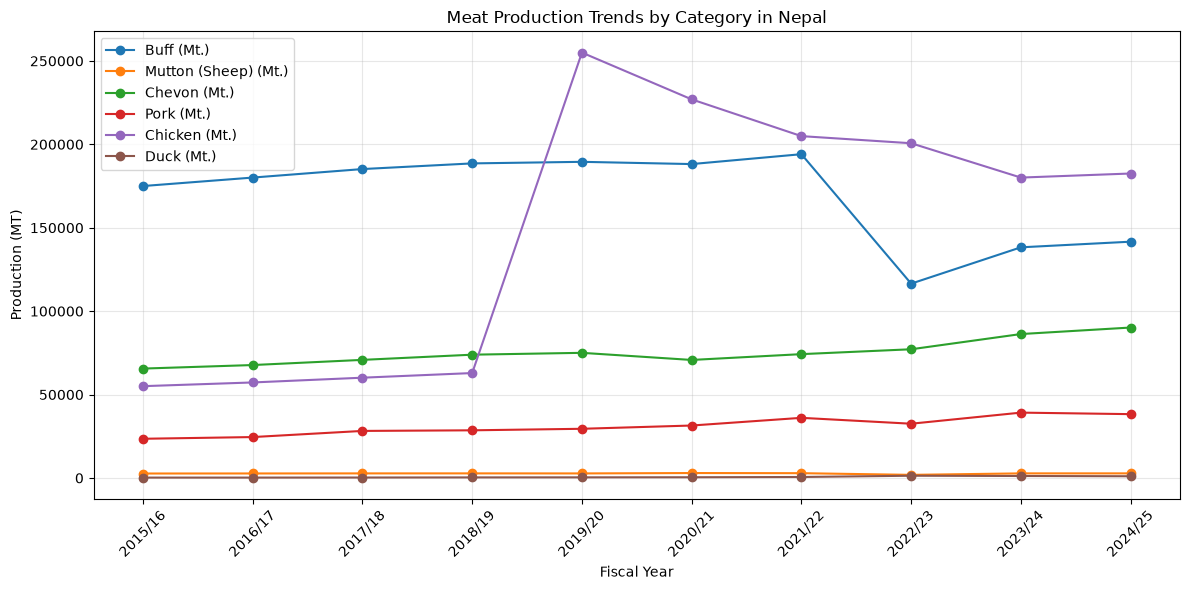

In [54]:
meat_categories = [
    "Buff (Mt.)",
    "Mutton (Sheep) (Mt.)",
    "Chevon (Mt.)",
    "Pork (Mt.)",
    "Chicken (Mt.)",
    "Duck (Mt.)"
]

plt.figure(figsize=(12, 6))

for category in meat_categories:
    plt.plot(
        meat_pivot.index,
        meat_pivot[category],
        marker="o",
        label=category
    )

plt.title("Meat Production Trends by Category in Nepal")
plt.xlabel("Fiscal Year")
plt.ylabel("Production (MT)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [47]:
egg_products = [
    "Egg Production (‘000 Number)",
    "Hen Egg (‘000 Number)",
    "Duck Egg(‘000 Number)"
]

egg_check = livestock_products_df[
    livestock_products_df["Product"].isin(egg_products)
]

egg_pivot = egg_check.pivot(
    index="Fiscal_Year",
    columns="Product",
    values="Value"
)

egg_pivot["Calculated_Egg_Total"] = egg_pivot[
    egg_products[1:]
].sum(axis=1)

egg_pivot["Difference"] = (
    egg_pivot["Egg Production (‘000 Number)"]
    - egg_pivot["Calculated_Egg_Total"]
)

display(egg_pivot)

Product,Duck Egg(‘000 Number),Egg Production (‘000 Number),Hen Egg (‘000 Number),Calculated_Egg_Total,Difference
Fiscal_Year,,,,,
2015/16,13906.0,1308072.0,1294166.0,1308072.0,0.0
2016/17,13984.0,1352296.0,1338312.0,1352296.0,0.0
2017/18,14241.0,1512265.0,1498024.0,1512265.0,0.0
2018/19,15009.0,1549689.0,1534680.0,1549689.0,0.0
2019/20,15474.0,1620000.0,1604526.0,1620000.0,0.0
2020/21,17930.0,1493550.0,1475620.0,1493550.0,0.0
2021/22,24223.0,1330602.0,1306380.0,1330603.0,-1.0
2022/23,60229.0,1607333.0,1547103.0,1607332.0,1.0
2023/24,42652.0,1645407.0,1602755.0,1645407.0,0.0


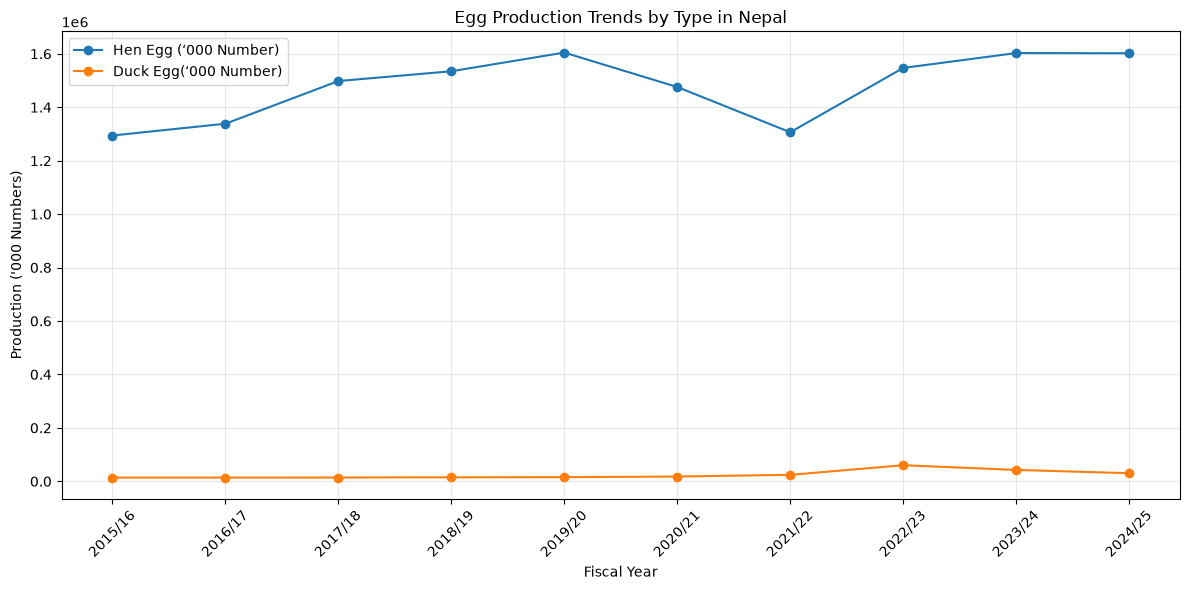

In [55]:
egg_products = [
    "Hen Egg (‘000 Number)",
    "Duck Egg(‘000 Number)"
]

plt.figure(figsize=(12, 6))

for product in egg_products:
    plt.plot(
        egg_pivot.index,
        egg_pivot[product],
        marker="o",
        label=product
    )

plt.title("Egg Production Trends by Type in Nepal")
plt.xlabel("Fiscal Year")
plt.ylabel("Production ('000 Numbers)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
# Filter wool and fish production
other_products = livestock_products_df[
    livestock_products_df["Product"].isin([
        "Wool Production(Kg.)",
        "Fish Production (Mt)"
    ])
]

# Display yearly production
wool_fish_pivot = other_products.pivot(
    index="Fiscal_Year",
    columns="Product",
    values="Value"
)

display(wool_fish_pivot)

Product,Fish Production (Mt),Wool Production(Kg.)
Fiscal_Year,,
2015/16,NaN,588348.0
2016/17,83898.0,594312.0
2017/18,86544.0,594639.0
2018/19,91832.0,589738.0
2019/20,97271.0,592686.0
2020/21,104623.0,583999.0
2021/22,108383.0,567411.0
2022/23,113736.0,381105.0
2023/24,123403.0,389742.0


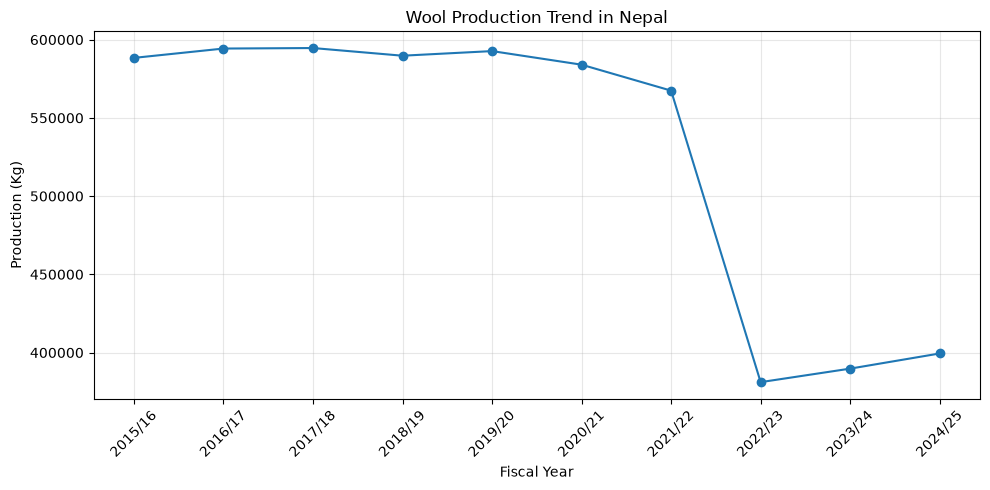

In [59]:
plt.figure(figsize=(10, 5))

plt.plot(
    wool_fish_pivot.index,
    wool_fish_pivot["Wool Production(Kg.)"],
    marker="o"
)

plt.title("Wool Production Trend in Nepal")
plt.xlabel("Fiscal Year")
plt.ylabel("Production (Kg)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

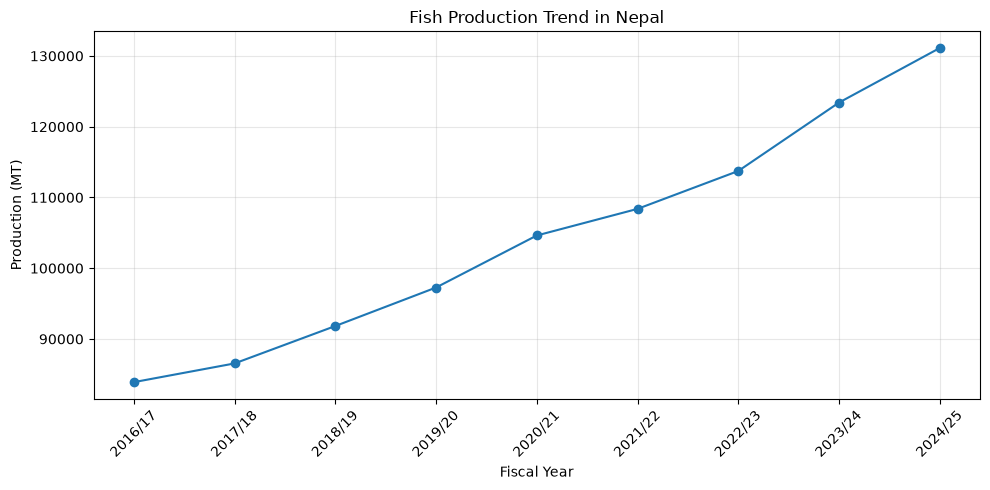

In [60]:
plt.figure(figsize=(10, 5))

plt.plot(
    wool_fish_pivot.index,
    wool_fish_pivot["Fish Production (Mt)"],
    marker="o"
)

plt.title("Fish Production Trend in Nepal")
plt.xlabel("Fiscal Year")
plt.ylabel("Production (MT)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [61]:
latest_livestock_products = livestock_products_df[
    livestock_products_df["Fiscal_Year"] == "2024/25"
].sort_values("Value", ascending=False)

display(latest_livestock_products)

,Fiscal_Year,Product,Value
0,2024/25,Milk Production (Mt.),2718177.0
10,2024/25,Egg Production (‘000 Number),1632289.0
11,2024/25,Hen Egg (‘000 Number),1601997.0
2,2024/25,Buff. Milk (Mt.),1416083.0
1,2024/25,Cow Milk (Mt.),1302094.0
3,2024/25,Meat (Net) Production (Mt.),456430.0
13,2024/25,Wool Production(Kg.),399432.0
8,2024/25,Chicken (Mt.),182516.0
4,2024/25,Buff (Mt.),141649.0
14,2024/25,Fish Production (Mt),131112.0


## Key Findings – Livestock Analysis

### 1. Livestock Population

- The dataset contains 110 records covering 11 livestock categories across 10 fiscal years, from 2015/16 to 2024/25.
- Fowl was the dominant livestock category throughout the analysis period. It accounted for approximately 71.59% of cumulative population records across the seven main livestock categories.
- Goat was the second-largest category, contributing approximately 13.75%, followed by cattle (6.96%) and buffaloes (4.80%).
- In 2024/25, the recorded populations were:
  - Fowl: 56,391,680
  - Goat: 15,954,080
  - Cattle: 5,141,391
  - Buffaloes: 3,294,723
  - Pigs: 1,480,832
  - Duck: 832,235
  - Sheep: 652,742
- Comparing 2015/16 with 2024/25, duck recorded the highest percentage increase (112.17%), followed by goat (45.22%) and pigs (14.68%).
- Cattle, buffaloes, sheep and fowl recorded declines of 29.60%, 36.26%, 18.47% and 17.83%, respectively, over the same period.

### 2. Productive Livestock

- Laying duck population increased by 77.92% between 2015/16 and 2024/25.
- Milking cow and laying hen populations recorded relatively small increases of 2.89% and 0.42%, respectively.
- Milking buffaloes recorded a decline of 28.73% over the analysis period.
- The productive livestock categories were analyzed separately from the main livestock categories to avoid double-counting overlapping populations.

### 3. Livestock Products

**Milk Production**
- Total milk production increased from 1,854,247 MT in 2015/16 to 2,718,177 MT in 2024/25.
- Buffalo milk production (1,416,083 MT) exceeded cow milk production (1,302,094 MT) in 2024/25.
- Buffalo milk contributed approximately 52.1% of total milk production, while cow milk contributed approximately 47.9%.
- The sum of cow milk and buffalo milk matched the reported total milk production across all 10 fiscal years.

**Meat Production**
- Total net meat production increased from 322,059 MT in 2015/16 to 456,430 MT in 2024/25.
- Chicken was the largest individual meat category in 2024/25, with 182,516 MT, followed by buffalo meat (141,649 MT) and chevon (90,186 MT).
- The calculated sum of individual meat categories matched the reported total in eight years.
- Minor differences of +1 MT in 2018/19 and -1 MT in 2021/22 were observed.

**Egg Production**
- Total egg production reached 1,632,289 thousand eggs in 2024/25.
- Hen eggs accounted for 1,601,997 thousand, while duck eggs accounted for 30,292 thousand.
- Hen eggs represented approximately 98.1% of total egg production.
- The calculated sum of hen and duck eggs matched the reported total in most years, with differences of ±1 thousand eggs in 2021/22 and 2022/23.

**Wool and Fish Production**
- Wool production declined from 588,348 kg in 2015/16 to 399,432 kg in 2024/25.
- Fish production increased from 83,898 MT in 2016/17 to 131,112 MT in 2024/25. No fish production record was available for 2015/16 in the dataset.

### 4. Data Quality Observations

- Livestock population data shows some substantial year-to-year fluctuations, particularly in 2022/23 for cattle, buffaloes and sheep. These changes should be interpreted cautiously.
- Chicken meat production increased sharply from 62,899 MT in 2018/19 to 255,001 MT in 2019/20. This unusual change is worth further investigation.
- Meat and egg production consistency checks identified only minor differences of 1 unit in a small number of fiscal years.
- Aggregate and component production records were analyzed separately to avoid double-counting.